In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams
rcParams["font.family"] = "Times New Roman"

In [17]:
df = pd.read_csv("../data/nyc_2024_data_cleaned.csv")
# print(df.shape)
# print(df.head())
print(df.dtypes)

primary_property_type_self            str
year_built                          int64
number_of_buildings                 int64
occupancy                           int64
site_eui_kbtu_ft                  float64
medical_office_gross_floor        float64
medical_office_number_of          float64
medical_office_number_of_1        float64
medical_office_number_of_2        float64
medical_office_percent_that       float64
medical_office_percent_that_1     float64
medical_office_weekly             float64
k_12_school_gross_floor_area      float64
multifamily_housing_government        str
multifamily_housing_gross         float64
multifamily_housing_number_1      float64
multifamily_housing_number_2      float64
multifamily_housing_number_3      float64
multifamily_housing_percent       float64
multifamily_housing_percent_1     float64
multifamily_housing_total_1       float64
multifamily_housing_number_5      float64
multifamily_housing_number_7      float64
multifamily_housing_resident      

***Target Variable***

In [18]:
y = df["site_eui_kbtu_ft"]
print(y.describe())
# print(y.isnull().sum())

count     19051.000000
mean        128.129269
std        2341.809912
min           0.000000
25%          49.200000
50%          68.200000
75%          89.500000
max      251650.000000
Name: site_eui_kbtu_ft, dtype: float64


In [19]:
percentiles = [0.50, 0.75, 0.90, 0.95, 0.98, 0.99, 0.995, 0.999, 1.00]
results = []

for p in percentiles:
    upper = y.quantile(p)

    results.append({
        "percentile (%)": p * 100,
        "Site EUI upper bound": upper,
        "records within this range": (y <= upper).sum(),
        "records exceed this range": (y > upper).sum(),
    })

percentile_summary = pd.DataFrame(results)
display(percentile_summary.round(2))

,percentile (%),Site EUI upper bound,records within this range,records exceed this range
0,50.0,68.20,9547,9504
1,75.0,89.50,14301,4750
2,90.0,122.00,17147,1904
3,95.0,164.60,18099,952
4,98.0,250.80,18670,381
5,99.0,368.70,18860,191
6,99.5,603.45,18955,96
7,99.9,4745.92,19031,20
8,100.0,251650.00,19051,0


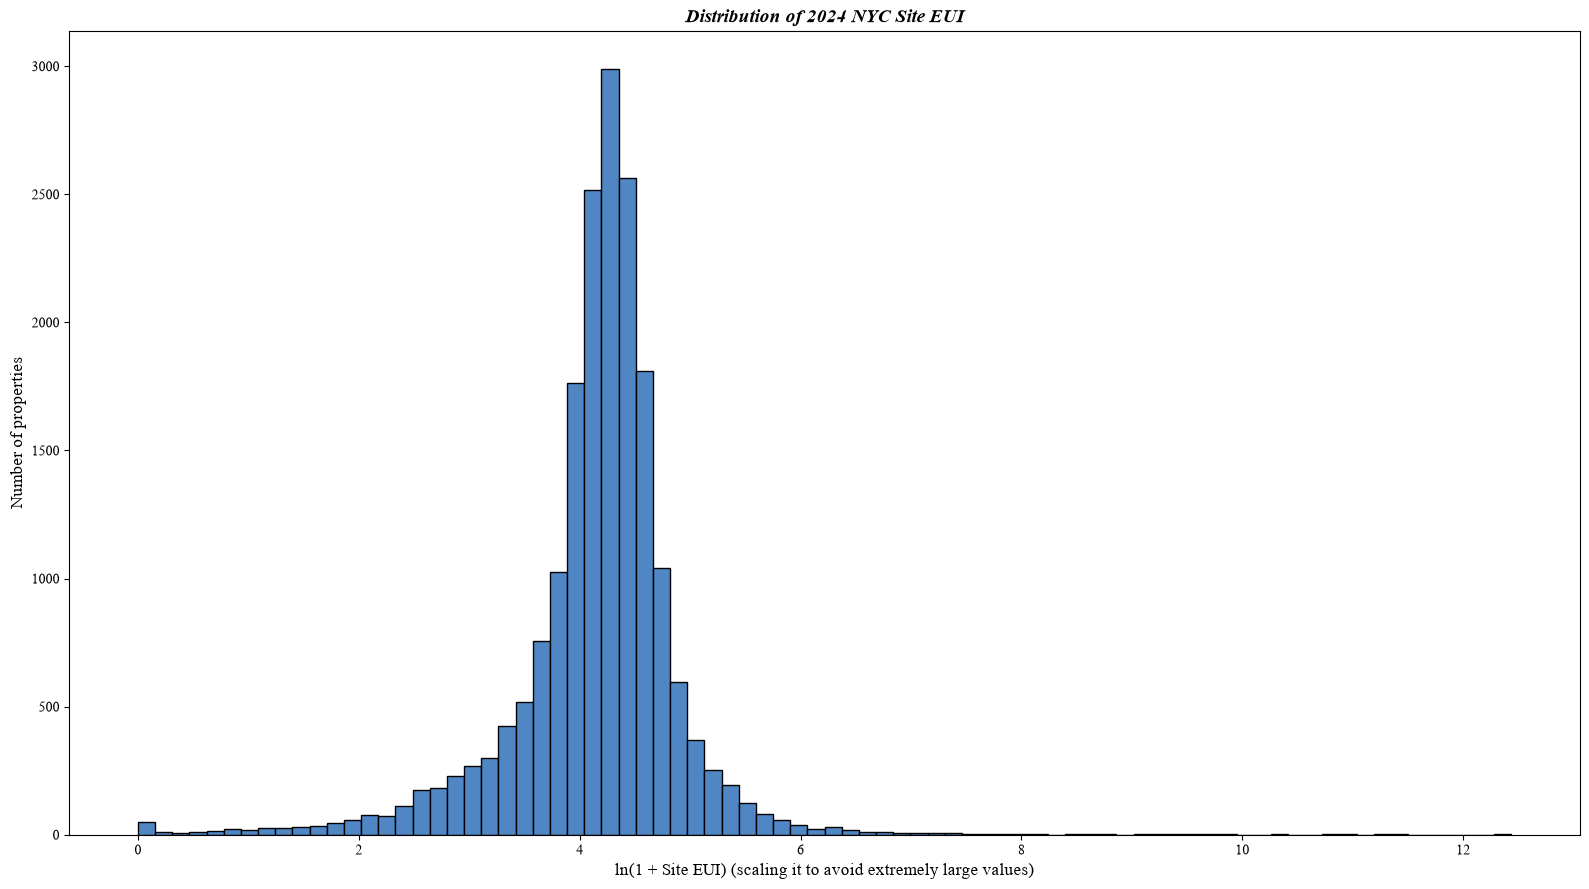

In [20]:
plt.figure(figsize=(16, 9))

plt.hist(np.log1p(y), bins=80, edgecolor="black", color="#5086C4")

plt.xlabel("ln(1 + Site EUI) (scaling it to avoid extremely large values)", fontsize=12)
plt.ylabel("Number of properties", fontsize=12)
plt.title("Distribution of 2024 NYC Site EUI", fontsize=14, fontweight="bold", style="italic")
# plt.grid(axis="y", linestyle="--", alpha=0.75)
plt.tight_layout()
plt.savefig("../figures/2024_nyc_site_eui_distribution_do_not_use_this.png", dpi=300)
plt.show()

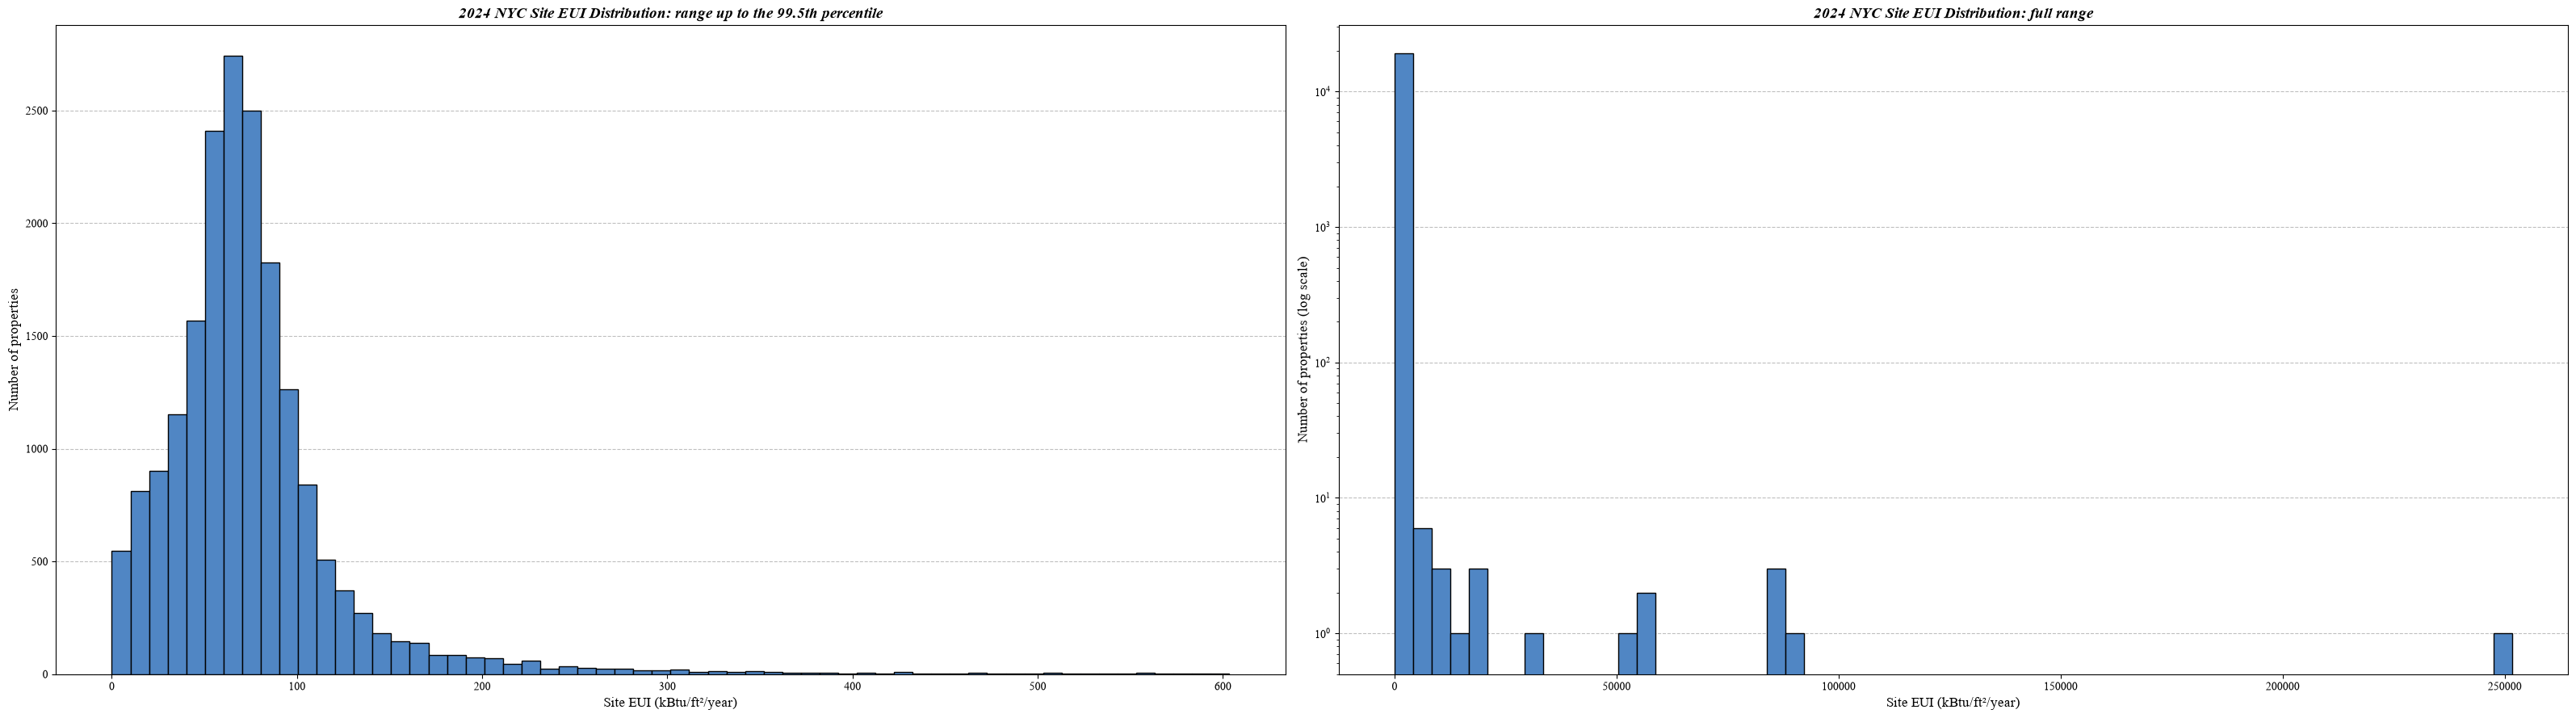

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(32, 9))

upper = y.quantile(0.995)

# display the main distribution: up to the 99.5th percentile to show the majority of the data without being skewed by extreme outliers
axes[0].hist(y, bins=60, range=(0, upper),edgecolor="black", color="#5086C4")
axes[0].set_title("2024 NYC Site EUI Distribution: range up to the 99.5th percentile", fontsize=14, fontweight="bold", style="italic")
axes[0].set_ylabel("Number of properties", fontsize=12)
axes[0].set_xlabel("Site EUI (kBtu/ft²/year)", fontsize=12)
axes[0].set_axisbelow(True)
axes[0].grid(axis="y", linestyle="--", alpha=0.8)

# display the full distribution: including extreme outliers, using a logarithmic scale to better visualize the data
axes[1].hist(y, bins=60, edgecolor="black", color="#5086C4")
axes[1].set_yscale("log")
axes[1].set_ylim(bottom=0.5)
axes[1].set_title("2024 NYC Site EUI Distribution: full range", fontsize=14, fontweight="bold", style="italic")
axes[1].set_ylabel("Number of properties (log scale)", fontsize=12)
axes[1].set_xlabel("Site EUI (kBtu/ft²/year)", fontsize=12)
axes[1].set_axisbelow(True)
axes[1].grid(axis="y", linestyle="--", alpha=0.8)

plt.tight_layout()
plt.savefig("../figures/2024_nyc_site_eui_distribution_clear_version.png", dpi=300)
plt.show()

In [64]:
correlations = (df.select_dtypes(include=[np.number]).corr())[y.name].drop(y.name)
print(correlations.sort_values(ascending=False, key=lambda x: x.abs()).round(4))

multifamily_housing_number_1      0.2811
multifamily_housing_total_1       0.2760
medical_office_number_of_1        0.1675
multifamily_housing_number_7      0.1436
restaurant_gross_floor_area       0.1377
restaurant_weekly_operating       0.1198
medical_office_gross_floor        0.1039
medical_office_weekly             0.0950
medical_office_number_of_2        0.0911
medical_office_number_of          0.0707
parking_open_parking_lot          0.0478
parking_partially_enclosed        0.0390
medical_office_percent_that_1     0.0387
medical_office_percent_that       0.0373
restaurant_worker_density         0.0299
k_12_school_gross_floor_area     -0.0215
multifamily_housing_percent      -0.0195
office_weekly_operating_hours     0.0185
retail_store_gross_floor         -0.0174
multifamily_housing_gross        -0.0172
multifamily_housing_number_3      0.0169
parking_completely_enclosed       0.0140
office_worker_density_number      0.0125
office_gross_floor_area_ft       -0.0112
retail_store_num

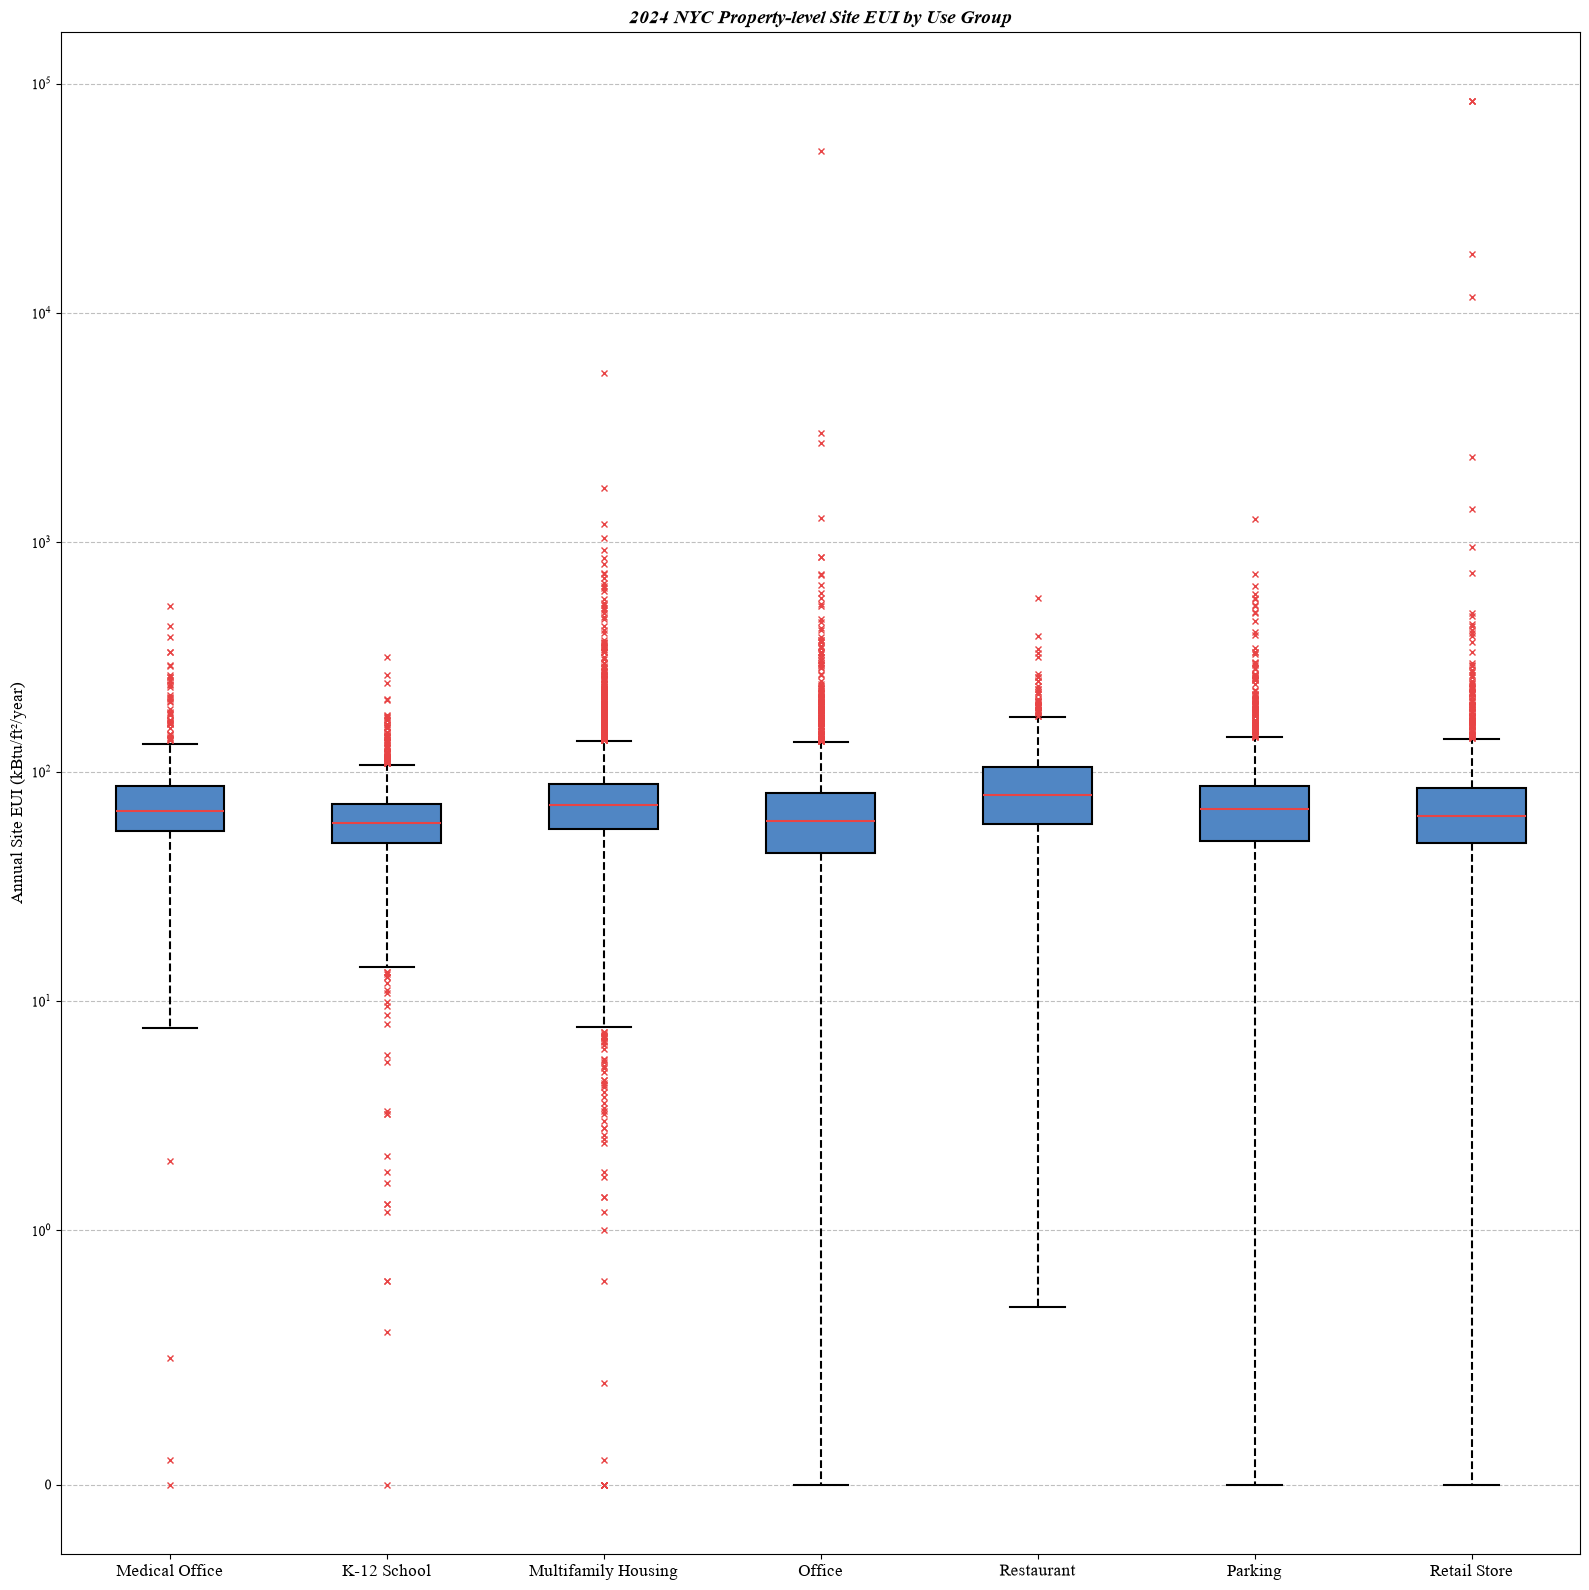

In [68]:
property_types = {
    "Medical Office": "medical_office_",
    "K-12 School": "k_12_school_",
    "Multifamily Housing": "multifamily_housing_",
    "Office": "office_",
    "Restaurant": "restaurant_",
    "Parking": "parking_",
    "Retail Store": "retail_store_",
}

group_values = []
group_names = []

for property_type, prefix in property_types.items():
    group_cols = [col for col in df.columns if col.startswith(prefix)]

    identifier = df[group_cols].notna().any(axis=1)  # seperate the properties that belong to this specific property type

    group_values.append(df.loc[identifier, "site_eui_kbtu_ft"].dropna())
    group_names.append(property_type)

fig, ax = plt.subplots(figsize=(16, 16))

ax.boxplot(group_values, patch_artist=True,
           boxprops={"facecolor": "#5086C4", "edgecolor": "black", "linewidth": 1.5},
           medianprops={"color": "#E84445", "linewidth": 1.5},
           flierprops={"markeredgecolor": "#E84445", "markerfacecolor": "#E84445", "markersize": 5, "marker": "x"},
           whiskerprops={"color": "black", "linewidth": 1.5, "linestyle": "--"},
           capprops={"color": "black", "linewidth": 1.5})
ax.set_yscale("symlog", linthresh=1)
ax.set_xticks(range(1, len(group_names) + 1))
ax.set_xticklabels(group_names, fontsize=12)

ax.set_title("2024 NYC Property-level Site EUI by Use Group", fontsize=14, fontweight="bold", style="italic")
ax.set_ylabel("Annual Site EUI (kBtu/ft²/year)", fontsize=12)
ax.set_axisbelow(True)
ax.grid(axis="y", linestyle="--", alpha=0.8)

plt.savefig("../figures/2024_nyc_property_level_site_eui_by_use_group.png", dpi=300)
plt.tight_layout()
plt.show()